In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import xema


In [17]:
# Figure 2 data: monthly generation by technology and reservoir volume
gen = xema.download_generation(2019, 2025)
res = xema.download_reservoirs("2019-01-01", "2025-12-31")

# capacity of each reservoir = volume / (pct / 100); the median removes rounding noise
cap = (res["volume_hm3"] / (res["pct"] / 100)).groupby(res["reservoir"]).median()
res = res.assign(capacity_hm3=res["reservoir"].map(cap))

# basin-level percentage = total volume / total capacity (not the mean of percentages)
basin = res.groupby("date").agg(
    volume=("volume_hm3", "sum"), capacity=("capacity_hm3", "sum")
)
basin = basin.assign(pct=100 * basin["volume"] / basin["capacity"])
basin_m = basin["pct"].resample("MS").mean()

gen_p = gen.pivot(index="date", columns="technology", values="value_mwh") / 1000  # GWh
print(gen_p.shape, cap.sum().round(1))


(84, 11) 694.4


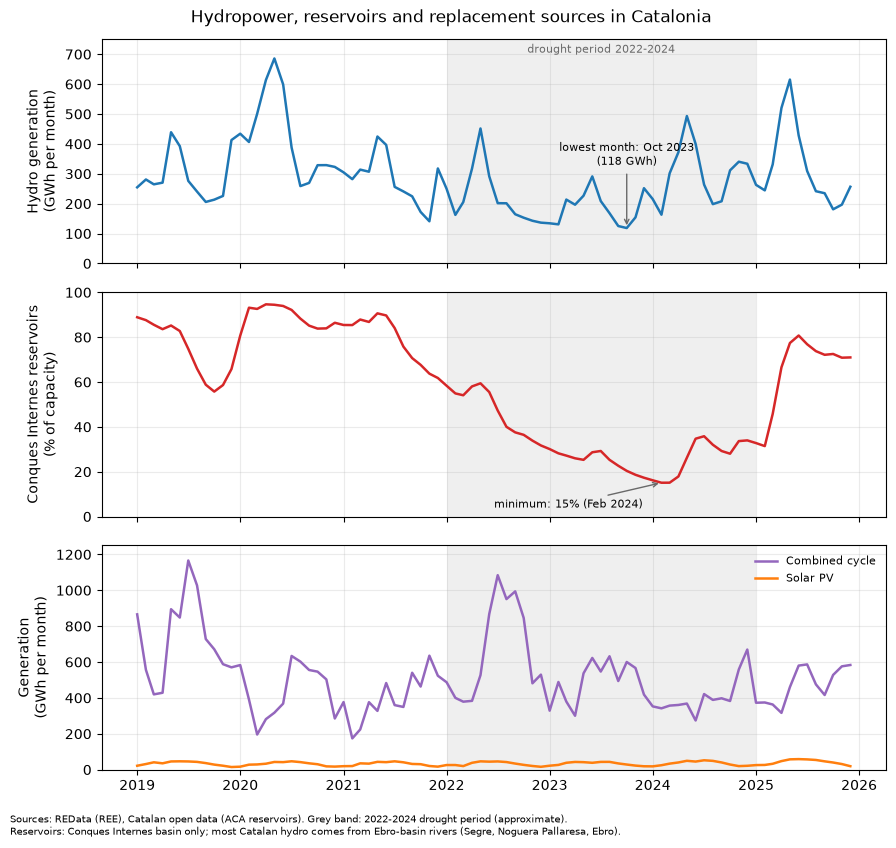

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True)
drought = (pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"))

axes[0].plot(gen_p.index, gen_p["Hidráulica"], color="tab:blue", lw=1.8)
axes[0].set_ylabel("Hydro generation\n(GWh per month)")
axes[0].set_ylim(0, 750)

axes[1].plot(basin_m.index, basin_m, color="tab:red", lw=1.8)
axes[1].set_ylabel("Conques Internes reservoirs\n(% of capacity)")
axes[1].set_ylim(0, 100)

# same y axis for both technologies, so their sizes can be compared directly
axes[2].plot(gen_p.index, gen_p["Ciclo combinado"], color="tab:purple", lw=1.8,
             label="Combined cycle")
axes[2].plot(gen_p.index, gen_p["Solar fotovoltaica"], color="tab:orange", lw=1.8,
             label="Solar PV")
axes[2].set_ylabel("Generation\n(GWh per month)")
axes[2].set_ylim(0, 1250)
axes[2].legend(frameon=False, fontsize=8, loc="upper right")

for ax in axes:
    ax.axvspan(*drought, color="grey", alpha=0.12, lw=0)
    ax.grid(alpha=0.25)

mid = drought[0] + (drought[1] - drought[0]) / 2
axes[0].text(mid, 735, "drought period 2022-2024", ha="center", va="top",
             fontsize=8, color="dimgrey")

h = gen_p["Hidráulica"]
axes[0].annotate(f"lowest month: {h.idxmin():%b %Y}\n({h.min():.0f} GWh)",
                 xy=(h.idxmin(), h.min()), xytext=(h.idxmin(), 330),
                 ha="center", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="dimgrey"))
axes[1].annotate(f"minimum: {basin_m.min():.0f}% ({basin_m.idxmin():%b %Y})",
                 xy=(basin_m.idxmin(), basin_m.min()),
                 xytext=(basin_m.idxmin() - pd.Timedelta(days=330), 4),
                 ha="center", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="dimgrey"))

fig.suptitle("Hydropower, reservoirs and replacement sources in Catalonia")
fig.text(0.01, 0.005,
         "Sources: REData (REE), Catalan open data (ACA reservoirs). Grey band: 2022-2024 "
         "drought period (approximate).\nReservoirs: Conques Internes basin only; most "
         "Catalan hydro comes from Ebro-basin rivers (Segre, Noguera Pallaresa, Ebro).",
         fontsize=7, ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.04, 1, 1))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "hydro_vs_reservoirs.png", dpi=200)
fig.savefig(out / "hydro_vs_reservoirs.svg")


In [19]:
# Rain test: monthly precipitation in the Pyrenees (XEMA variable 1300, valley stations)
pyr = ["Y4", "W5", "CJ", "CD", "CT", "DP", "YA", "WQ", "CP", "XQ", "YC", "XH", "YG"]
rain = {}
for st in pyr:
    dd = xema.download_daily(st, "1300", "2019-01-01", "2025-12-31").set_index("date")["value"]
    mm = dd.resample("MS").agg(["sum", "count"])
    rain[st] = mm["sum"].where(mm["count"] >= 25)  # drop months with too few days
rain_m = pd.DataFrame(rain).mean(axis=1)  # mean monthly total over the stations (mm)
hydro = gen_p["Hidráulica"]


def anomaly(s):
    # value minus the mean of the same calendar month: removes the seasonal cycle
    return s - s.groupby(s.index.month).transform("mean")


h_an, r_an = anomaly(hydro), anomaly(rain_m)
xcorr = pd.Series({k: h_an.corr(r_an.shift(k)) for k in range(-3, 7)})  # k > 0: rain leads
r6 = r_an.rolling(6).sum().shift(1)  # rain anomaly accumulated over the previous 6 months
print("cross-correlation by lag:", xcorr.round(2).to_dict())
print("hydro anomaly vs previous 6-month rain anomaly:", round(h_an.corr(r6), 2))

annual = pd.DataFrame({"hydro_gwh": hydro.resample("YS").sum(),
                       "rain_mm": rain_m.resample("YS").sum()})
annual.index = annual.index.year
print(annual.round(0).T.to_string())
print("annual correlation:", round(annual.corr().iloc[0, 1], 2))


cross-correlation by lag: {-3: 0.3, -2: 0.14, -1: 0.1, 0: 0.34, 1: 0.49, 2: 0.42, 3: 0.25, 4: 0.2, 5: 0.24, 6: 0.36}
hydro anomaly vs previous 6-month rain anomaly: 0.72
date         2019    2020    2021    2022    2023    2024    2025
hydro_gwh  3477.0  5136.0  3382.0  2678.0  2220.0  3600.0  3823.0
rain_mm     654.0   747.0   566.0   546.0   459.0   763.0   775.0
annual correlation: 0.8


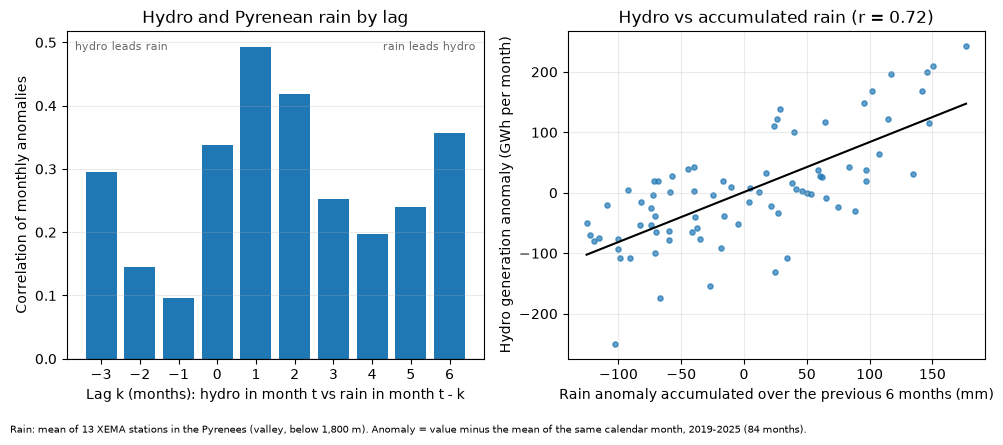

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.4))

ax1.bar(xcorr.index, xcorr.values, color="tab:blue")
ax1.axhline(0, color="black", lw=0.8)
ax1.set_xticks(list(xcorr.index))
ax1.set_xlabel("Lag k (months): hydro in month t vs rain in month t - k")
ax1.set_ylabel("Correlation of monthly anomalies")
ax1.set_title("Hydro and Pyrenean rain by lag")
ax1.text(0.02, 0.97, "hydro leads rain", transform=ax1.transAxes, va="top",
         fontsize=8, color="dimgrey")
ax1.text(0.98, 0.97, "rain leads hydro", transform=ax1.transAxes, va="top",
         ha="right", fontsize=8, color="dimgrey")
ax1.grid(alpha=0.25, axis="y")

ok = pd.concat([r6, h_an], axis=1, keys=["x", "y"]).dropna()
ax2.scatter(ok["x"], ok["y"], s=14, alpha=0.7, color="tab:blue")
slope, intercept = np.polyfit(ok["x"], ok["y"], 1)
xs = np.array([ok["x"].min(), ok["x"].max()])
ax2.plot(xs, intercept + slope * xs, color="black", lw=1.5)
ax2.set_xlabel("Rain anomaly accumulated over the previous 6 months (mm)")
ax2.set_ylabel("Hydro generation anomaly (GWh per month)")
ax2.set_title(f"Hydro vs accumulated rain (r = {ok['x'].corr(ok['y']):.2f})")
ax2.grid(alpha=0.25)

fig.text(0.01, 0.005,
         "Rain: mean of 13 XEMA stations in the Pyrenees (valley, below 1,800 m). Anomaly = "
         "value minus the mean of the same calendar month, 2019-2025 (84 months).",
         fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "hydro_vs_rain.png", dpi=200)
fig.savefig(out / "hydro_vs_rain.svg")


In [21]:
# Main figure 2: who covers the change in generation? Annual change by source (GWh)
ind = xema.download_indicators("2019-01-01", "2025-12-31")
imports_y = ind.set_index("date")["net_imports_gwh"].resample("YS").sum()

groups = {
    "Hydro": ["Hidráulica"],
    "Combined cycle": ["Ciclo combinado"],
    "Nuclear": ["Nuclear"],
    "Cogeneration": ["Cogeneración"],
    "Wind": ["Eólica"],
    "Solar PV": ["Solar fotovoltaica"],
    "Other": ["Solar térmica", "Otras renovables",
              "Residuos no renovables", "Residuos renovables"],
}
annual_src = pd.DataFrame(
    {name: gen_p[cols].sum(axis=1).resample("YS").sum() for name, cols in groups.items()}
)
annual_src["Net imports"] = imports_y
change = annual_src.diff().dropna()  # change versus the previous year (GWh)
change.index = change.index.year
change = change.loc[2022:]  # the drought years and after
print(change.round(0).T.to_string())


date              2022    2023    2024   2025
Hydro           -704.0  -458.0  1381.0  222.0
Combined cycle  3097.0 -2014.0 -1042.0  760.0
Nuclear          600.0 -1437.0  -370.0  634.0
Cogeneration   -1157.0   199.0  -412.0 -418.0
Wind            -179.0   623.0  -241.0 -476.0
Solar PV           5.0    15.0    21.0   74.0
Other            -18.0   -25.0   -45.0  -49.0
Net imports    -1285.0  2575.0   224.0  330.0


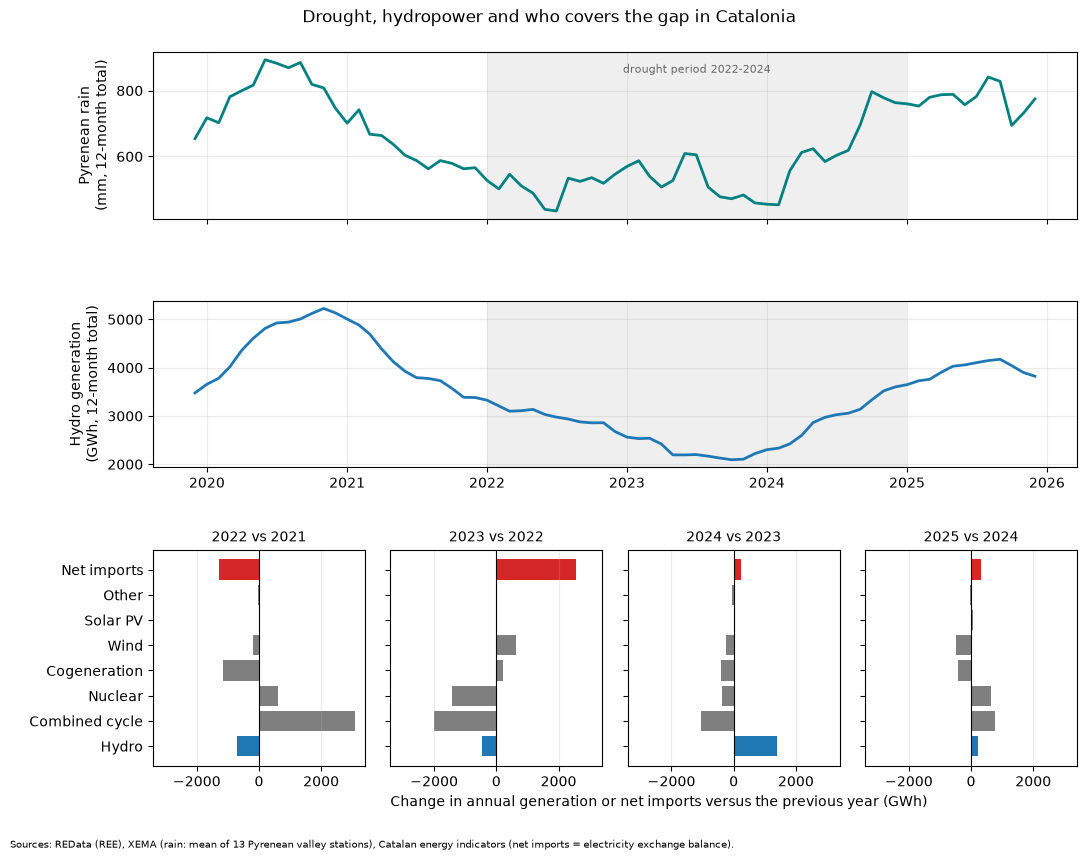

In [22]:
fig = plt.figure(figsize=(11, 8.6))
gs = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1.3], hspace=0.45, wspace=0.12)
ax_r = fig.add_subplot(gs[0, :])
ax_h = fig.add_subplot(gs[1, :], sharex=ax_r)
drought = (pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"))

rain12 = rain_m.rolling(12).sum()
hydro12 = hydro.rolling(12).sum()
ax_r.plot(rain12.index, rain12, color="teal", lw=2)
ax_r.set_ylabel("Pyrenean rain\n(mm, 12-month total)")
ax_h.plot(hydro12.index, hydro12, color="tab:blue", lw=2)
ax_h.set_ylabel("Hydro generation\n(GWh, 12-month total)")
for ax in (ax_r, ax_h):
    ax.axvspan(*drought, color="grey", alpha=0.12, lw=0)
    ax.grid(alpha=0.25)
plt.setp(ax_r.get_xticklabels(), visible=False)
ax_r.text(drought[0] + (drought[1] - drought[0]) / 2, 0.93, "drought period 2022-2024",
          transform=ax_r.get_xaxis_transform(), ha="center", va="top", fontsize=8,
          color="dimgrey")

names = list(change.columns)
colors = ["tab:blue" if n == "Hydro" else "tab:red" if n == "Net imports" else "tab:grey"
          for n in names]
lim = 1.1 * change.abs().to_numpy().max()
bar_axes = []
for j, year in enumerate(change.index):
    ax = fig.add_subplot(gs[2, j], sharex=bar_axes[0] if bar_axes else None,
                         sharey=bar_axes[0] if bar_axes else None)
    ax.barh(names, change.loc[year], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{year} vs {year - 1}", fontsize=10)
    ax.set_xlim(-lim, lim)
    ax.invert_yaxis()
    ax.grid(alpha=0.25, axis="x")
    if j > 0:
        plt.setp(ax.get_yticklabels(), visible=False)
    bar_axes.append(ax)
bar_axes[1].set_xlabel("Change in annual generation or net imports versus the previous "
                       "year (GWh)", loc="left")

fig.suptitle("Drought, hydropower and who covers the gap in Catalonia")
fig.text(0.01, 0.005,
         "Sources: REData (REE), XEMA (rain: mean of 13 Pyrenean valley stations), Catalan "
         "energy indicators (net imports = electricity exchange balance).",
         fontsize=7, ha="left")
fig.subplots_adjust(left=0.14, right=0.98, top=0.93, bottom=0.1)

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "hydro_drought_replacement.png", dpi=200)
fig.savefig(out / "hydro_drought_replacement.svg")
